In [1]:
%pip install -q segmentation-models-pytorch

In [5]:
import sys
import subprocess

print("Installing library...")

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "segmentation-models-pytorch"
])

print("Installation completed!")

Installing library...
Installation completed!


In [6]:
import segmentation_models_pytorch as smp

print("SUCCESS! Library is working.")
print("Version:", smp.__version__)

SUCCESS! Library is working.
Version: 0.6.0


In [7]:
import numpy as np
import torch
import segmentation_models_pytorch as smp
from google.colab import drive
from torch.utils.data import TensorDataset, DataLoader

drive.mount("/content/drive")

FOLDER = "/content/drive/MyDrive/LULC_Project"

data = np.load(f"{FOLDER}/training_dataset.npz")
split = np.load(f"{FOLDER}/geographic_split.npz")

X = data["X"]
Y = data["Y"]
test_idx = split["test_idx"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights=None,
    in_channels=2,
    classes=11
).to(device)

model.load_state_dict(
    torch.load(
        f"{FOLDER}/unet_sentinel1.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Best U-Net model loaded successfully!")
print("Device:", device)
print("Test patches:", len(test_idx))

Mounted at /content/drive
Best U-Net model loaded successfully!
Device: cuda
Test patches: 9


In [8]:
test_data = TensorDataset(
    torch.from_numpy(X[test_idx]).float(),
    torch.from_numpy(Y[test_idx].astype(np.int64))
)

test_loader = DataLoader(
    test_data,
    batch_size=2,
    shuffle=False
)

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.append(predictions.cpu().numpy())
        all_labels.append(labels.numpy())

y_pred = np.concatenate(all_predictions)
y_true = np.concatenate(all_labels)

print("Prediction shape:", y_pred.shape)
print("Ground truth shape:", y_true.shape)
print("Predictions generated successfully!")

Prediction shape: (9, 256, 256)
Ground truth shape: (9, 256, 256)
Predictions generated successfully!


In [9]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

CLASS_NAMES = [
    "Trees", "Shrubland", "Grassland",
    "Cropland", "Built-up", "Bare land",
    "Snow/Ice", "Water", "Wetland",
    "Mangroves", "Moss/Lichen"
]

# Convert 2D segmentation maps into 1D arrays
true_flat = y_true.flatten()
pred_flat = y_pred.flatten()

# Remove ignored pixels, if any
valid = true_flat != 255

true_flat = true_flat[valid]
pred_flat = pred_flat[valid]

# Confusion matrix
cm = confusion_matrix(
    true_flat,
    pred_flat,
    labels=np.arange(11)
)

# Precision, recall and F1
precision, recall, f1, support = (
    precision_recall_fscore_support(
        true_flat,
        pred_flat,
        labels=np.arange(11),
        zero_division=0
    )
)

# Calculate IoU for each class
tp = np.diag(cm)
fp = cm.sum(axis=0) - tp
fn = cm.sum(axis=1) - tp

union = tp + fp + fn

iou = np.divide(
    tp,
    union,
    out=np.full(11, np.nan, dtype=float),
    where=union > 0
)

# Classes absent from test labels cannot be evaluated
iou[support == 0] = np.nan

results = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Pixels": support,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "IoU": iou
})

results.loc[
    results["Pixels"] == 0,
    ["Precision", "Recall", "F1"]
] = np.nan

overall_accuracy = accuracy_score(
    true_flat,
    pred_flat
)

mean_iou = np.nanmean(iou)
mean_f1 = np.nanmean(results["F1"])

print("===== MODEL EVALUATION =====")
print(f"Overall Accuracy: {overall_accuracy:.4f}")
print(f"Mean IoU:         {mean_iou:.4f}")
print(f"Mean F1-score:    {mean_f1:.4f}")

print("\nPer-class performance:")
display(results.round(4))

===== MODEL EVALUATION =====
Overall Accuracy: 0.7760
Mean IoU:         0.4270
Mean F1-score:    0.5321

Per-class performance:


,Class,Pixels,Precision,Recall,F1,IoU
0,Trees,272864,0.9463,0.7909,0.8616,0.7569
1,Shrubland,0,NaN,NaN,NaN,NaN
2,Grassland,162128,0.6621,0.8273,0.7356,0.5817
3,Cropland,94825,0.7428,0.6400,0.6875,0.5239
4,Built-up,56889,0.6052,0.7996,0.6889,0.5255
5,Bare land,1168,0.0000,0.0000,0.0000,0.0000
6,Snow/Ice,0,NaN,NaN,NaN,NaN
7,Water,1949,0.6907,0.8225,0.7508,0.6010
8,Wetland,1,0.0000,0.0000,0.0000,0.0000
9,Mangroves,0,NaN,NaN,NaN,NaN


In [10]:
import os

results.to_csv(
    os.path.join(FOLDER, "evaluation_metrics.csv"),
    index=False
)

np.save(
    os.path.join(FOLDER, "confusion_matrix.npy"),
    cm
)

np.savez_compressed(
    os.path.join(FOLDER, "test_predictions.npz"),
    y_true=y_true,
    y_pred=y_pred
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


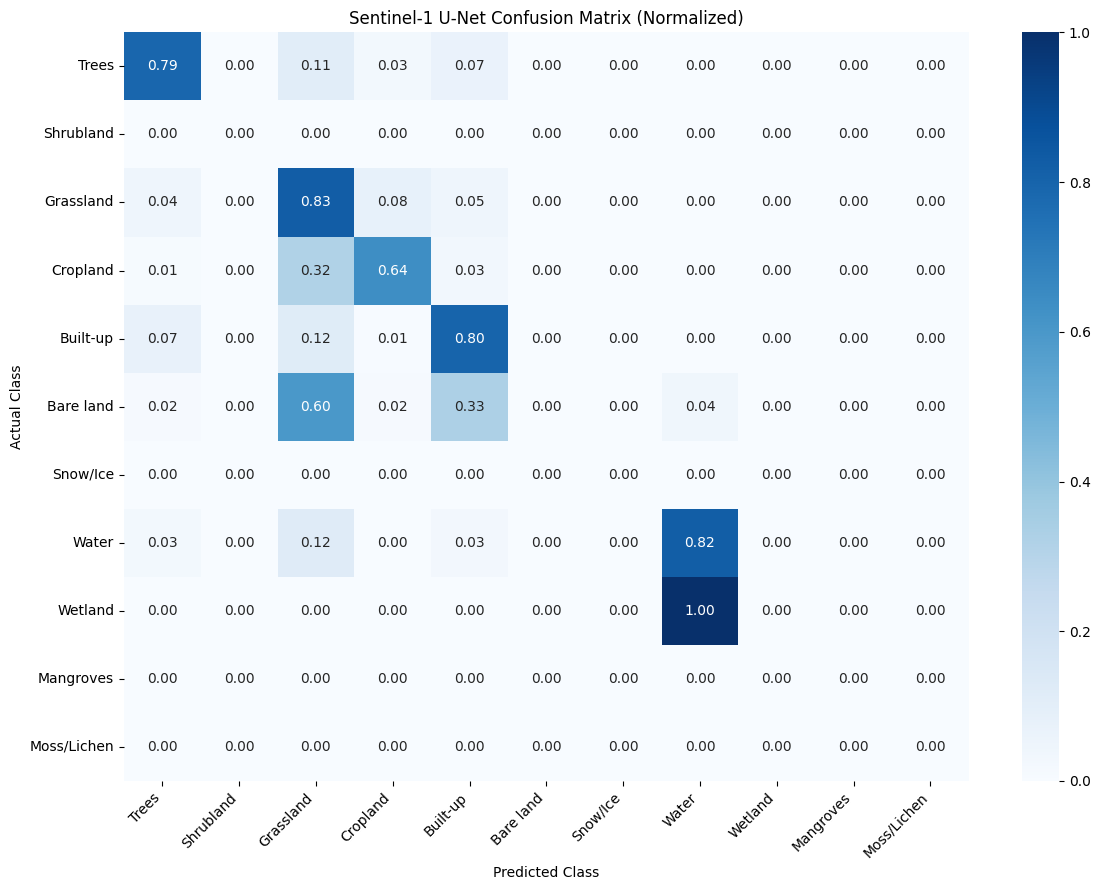

Confusion matrix saved successfully!


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 9))

# Normalize by the number of reference pixels per class
row_totals = cm.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm.astype(float),
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Sentinel-1 U-Net Confusion Matrix (Normalized)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    f"{FOLDER}/confusion_matrix.png",
    dpi=200
)

plt.show()

print("Confusion matrix saved successfully!")

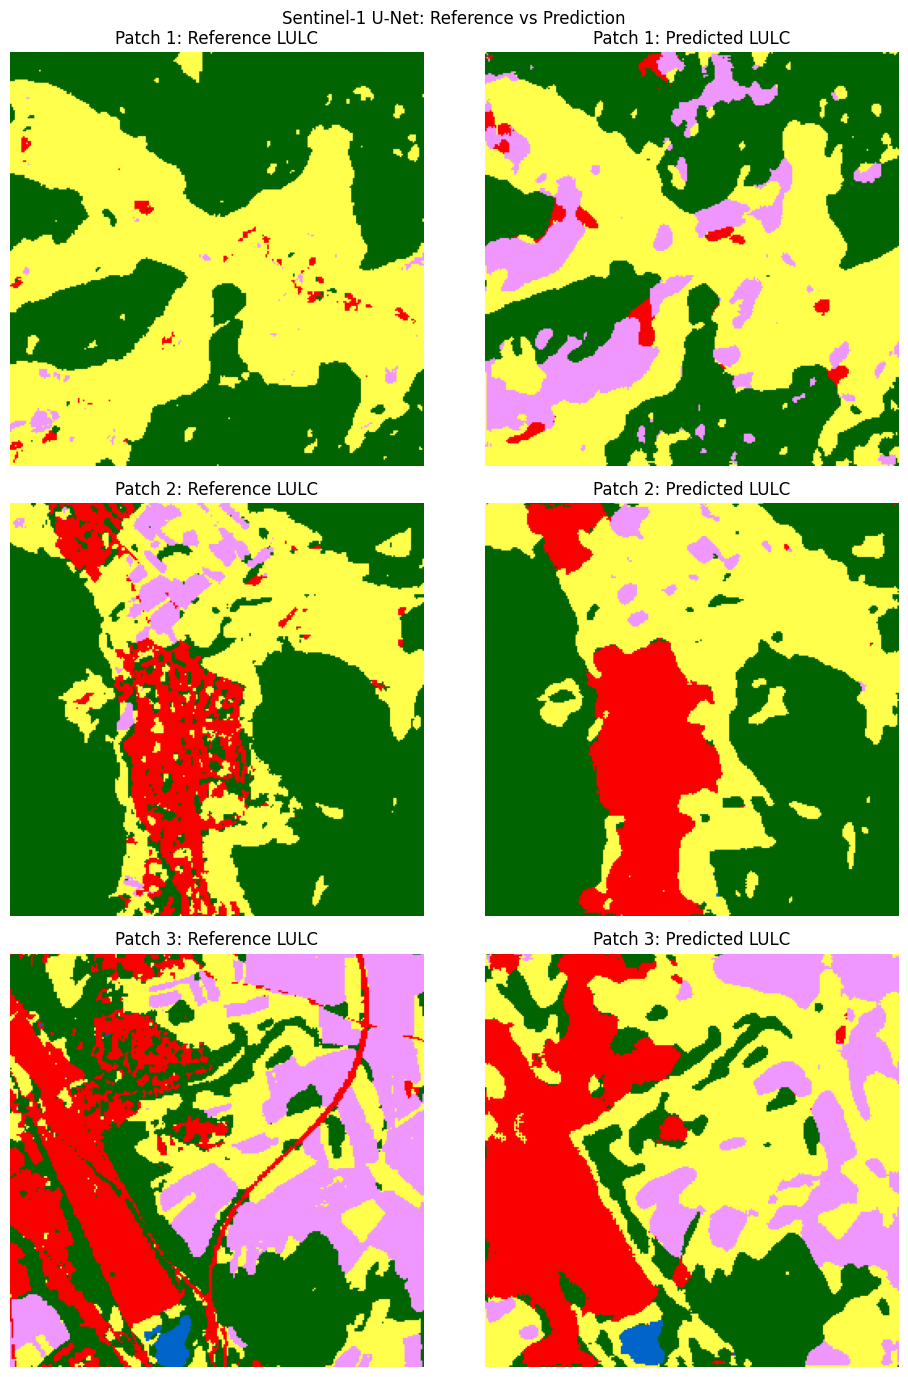

Prediction comparison saved successfully!


In [12]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

colors = [
    "#006400", "#ffbb22", "#ffff4c",
    "#f096ff", "#fa0000", "#b4b4b4",
    "#f0f0f0", "#0064c8", "#0096a0",
    "#00cf75", "#fae6a0"
]

cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(-0.5, 11.5, 1), cmap.N)

fig, axes = plt.subplots(3, 2, figsize=(10, 14))

for i in range(3):
    axes[i, 0].imshow(y_true[i], cmap=cmap, norm=norm)
    axes[i, 0].set_title(f"Patch {i+1}: Reference LULC")

    axes[i, 1].imshow(y_pred[i], cmap=cmap, norm=norm)
    axes[i, 1].set_title(f"Patch {i+1}: Predicted LULC")

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle("Sentinel-1 U-Net: Reference vs Prediction")
plt.tight_layout()

plt.savefig(
    f"{FOLDER}/prediction_comparison.png",
    dpi=200
)

plt.show()

print("Prediction comparison saved successfully!")